# Activity 2.2.6 Sentiment analysis and text classification

In this activity, you will build a sentiment analysis model using Python and a data set of customer reviews. You will preprocess the data and fine-tune, evaluate, and test the model.


## Objective
In this activity, you will download a data set from Hugging Face and conduct text classification on it. Your objective is to analyse how different parameter choices affect the performance of a sentiment classifier.

You will complete this in your Notebook, where you will:

- create and train sentiment classifier RNN models
- evaluate model performance.



## Assessment criteria

By completing this activity, you will be able to provide evidence that you can:
*   apply various text preprocessing techniques and representation methods to preprocess and analyse textual data.
*   comprehend and implement different types of recurrent neural networks (RNNs) and understand their applications in NLP.
*   build and fine-tune advanced NLP models for specific natural language processing tasks.


## Activity guidance

1. Install the necessary packages that will be useful in this activity
2. Load the dataset sst5 from hugging face (https://huggingface.co/datasets/SetFit/sst5)

3. Create dataframes of the train and train split
4. Split the train dataframe into train and validation in the ratio of 8:2
5. Preprocess the dataset, set the maximum size to 200, vocabulary size to 30000
6. During tokenisation, mark out of vocabulary words as "[OOV]"
7. Pad your sequences with special tokens
8. Train a sentiment classifier on the dataset and compare different models for text classification
9.Train for 5 epochs
- Train with a vanilla RNN
- Train with an LSTM
- Is there any difference between a GRU and an LSTM?
- Train with a bidirectional LSTM
10. Comment on the performance of all the models


In [ ]:
#In this activity, you will be required to download a dataset from huggingface and perfom the text classification on the the dataset
#You will be required to study the impact of different different parameter choices on the classification perfomance of sentiment classifier


#1. Install the necessary packages that will be useful in this  activity
#2. Load the dataset sst5 from hugginface (https://huggingface.co/datasets/SetFit/sst5)
#3.Create dataframes of the train and train split
#4 Split the train dataframe into train and validation in the ratio of 8:2
#5 Preprocess the dataset,  set the maximum size to 200, vocabulary size to 30000
#6. During tokenization, mark out of vocabulary words as "<OOV>"
#7 Pad your sequences with special tokens
#8. Train a sentiment classifier on the dataset and compare different models for text classification
# Train for 5 epochs
#    - Train with a vanilla RNN
#    - Train with an LSTM
#    - Is there any difference between a GRU and an LSTM?
#    - Train with a bidirectional LSTM
# Comment on the perfomance of all the models

## Import and Install libraries

In [1]:
#1. Install the necessary packages that will be useful in this  activity
!pip install datasets
!pip install tensorflow numpy

In [3]:
import tensorflow as tf
import numpy as np
import pandas as pd

In [4]:
#2. Load the dataset sst5 from hugginface (https://huggingface.co/datasets/SetFit/sst5)
from datasets import load_dataset
dataset = load_dataset('SetFit/sst5')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:124: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/421 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


train.jsonl:   0%|          | 0.00/1.32M [00:00<?, ?B/s]

dev.jsonl:   0%|          | 0.00/171k [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/343k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/8544 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1101 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2210 [00:00<?, ? examples/s]

In [5]:
#3.Create dataframes of the train and train split
train_df = pd.DataFrame(dataset['train'])
test_df = pd.DataFrame(dataset['test'])

In [6]:
#4 Split the train dataframe into train and validation in the ratio of 8:2
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=42)

In [7]:
#5 Preprocess the dataset,  set the maximum size to 200, vocabulary size to 30000
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Tokenize the text
tokenizer = Tokenizer(num_words=30000, oov_token="[OOV]")
tokenizer.fit_on_texts(train_df['text'])

In [8]:
#6. During tokenization, mark out of vocabulary words as "<OOV>"
train_sequences = tokenizer.texts_to_sequences(train_df['text'])
val_sequences = tokenizer.texts_to_sequences(val_df['text'])
test_sequences = tokenizer.texts_to_sequences(test_df['text'])

In [9]:
#7 Pad your sequences with special tokens
# Pad the sequences
train_padded = pad_sequences(train_sequences, maxlen=200, padding='post', truncating='post')
val_padded = pad_sequences(val_sequences, maxlen=200, padding='post', truncating='post')
test_padded = pad_sequences(test_sequences, maxlen=200, padding='post', truncating='post')
print("Vocabulary size:", len(tokenizer.word_index))
print("Sample padded sequence:", train_padded[0])

Vocabulary size: 13813
Sample padded sequence: [ 74 123  45  49  63   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0]


In [10]:
#8. Train a sentiment classifier on the dataset and compare different models for text classification
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Bidirectional, Dense
from sklearn.metrics import accuracy_score

# Convert labels to numpy arrays
train_labels = np.array(train_df['label'])
val_labels = np.array(val_df['label'])
test_labels = np.array(test_df['label'])

print("Label sample:", train_labels[:5])
print("Unique labels:", np.unique(train_labels))

Label sample: [3 2 3 1 1]
Unique labels: [0 1 2 3 4]


This is a 5-class sentiment analysis problem:

0 - Very negative
1 - Negative
2 - Neutral
3 - Positive
4 - Very positive

In [11]:
# Train for 5 epochs
# Train with a vanilla RNN
model_rnn = Sequential([
    Embedding(input_dim=len(tokenizer.word_index)+1, output_dim=128),
    SimpleRNN(64),
    Dense(5, activation='softmax')
])
model_rnn.compile(loss='<sheet-id>', optimizer='adam', metrics=['accuracy'])

history_rnn = model_rnn.fit(train_padded, train_labels, epochs=5, validation_data=(val_padded, val_labels))

Epoch 1/5


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


214/214 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - accuracy: 0.2610 - loss: 1.5774 - val_accuracy: 0.2779 - val_loss: 1.5655
Epoch 2/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.2601 - loss: 1.5951 - val_accuracy: 0.2820 - val_loss: 1.5765
Epoch 3/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.2568 - loss: 1.5837 - val_accuracy: 0.2411 - val_loss: 1.5813
Epoch 4/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.2609 - loss: 1.5780 - val_accuracy: 0.2762 - val_loss: 1.5766
Epoch 5/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - accuracy: 0.2505 - loss: 1.5766 - val_accuracy: 0.2709 - val_loss: 1.5657


In [12]:
loss_rnn, acc_rnn = model_rnn.evaluate(test_padded, test_labels)
print("Vanilla RNN Test Accuracy:", acc_rnn)

70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2330 - loss: 1.5874
Vanilla RNN Test Accuracy: 0.23303167521953583


In [13]:
# Train with an LSTM
model_lstm = Sequential([
    Embedding(input_dim=len(tokenizer.word_index)+1, output_dim=128),
    LSTM(64),
    Dense(5, activation='softmax')
])
model_lstm.compile(loss='<sheet-id>', optimizer='adam', metrics=['accuracy'])

history_lstm = model_lstm.fit(train_padded, train_labels, epochs=5, validation_data=(val_padded, val_labels))

Epoch 1/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 22s 96ms/step - accuracy: 0.2708 - loss: 1.5742 - val_accuracy: 0.2779 - val_loss: 1.5627
Epoch 2/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 41s 96ms/step - accuracy: 0.2669 - loss: 1.5722 - val_accuracy: 0.2703 - val_loss: 1.5621
Epoch 3/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - accuracy: 0.2653 - loss: 1.5714 - val_accuracy: 0.2779 - val_loss: 1.5664
Epoch 4/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 19s 90ms/step - accuracy: 0.2612 - loss: 1.5720 - val_accuracy: 0.2779 - val_loss: 1.5627
Epoch 5/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 20s 89ms/step - accuracy: 0.2727 - loss: 1.5710 - val_accuracy: 0.2779 - val_loss: 1.5618


In [14]:
loss_lstm, acc_lstm = model_lstm.evaluate(test_padded, test_labels)
print("LSTM Test Accuracy:", acc_lstm)

70/70 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.2308 - loss: 1.5852
LSTM Test Accuracy: 0.23076923191547394


Is there any difference between a GRU and an LSTM?

LSTM is slightly more stable than RNN (less fluctuation). But accuracy is still around 27% — not much improvement yet.
LSTM took longer to train as expected.
LSTM is very slightly worse than RNN on test.

In [15]:
# Train with a bidirectional LSTM
model_bilstm = Sequential([
    Embedding(input_dim=len(tokenizer.word_index)+1, output_dim=128),
    Bidirectional(LSTM(64)),
    Dense(5, activation='softmax')
])
model_bilstm.compile(loss='<sheet-id>', optimizer='adam', metrics=['accuracy'])

history_bilstm = model_bilstm.fit(train_padded, train_labels, epochs=5, validation_data=(val_padded, val_labels))

Epoch 1/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 37s 160ms/step - accuracy: 0.3280 - loss: 1.5012 - val_accuracy: 0.3868 - val_loss: 1.3895
Epoch 2/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 42s 164ms/step - accuracy: 0.4903 - loss: 1.1661 - val_accuracy: 0.4073 - val_loss: 1.3443
Epoch 3/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 35s 165ms/step - accuracy: 0.6734 - loss: 0.8167 - val_accuracy: 0.3745 - val_loss: 1.5269
Epoch 4/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 40s 159ms/step - accuracy: 0.8312 - loss: 0.4810 - val_accuracy: 0.3622 - val_loss: 1.9062
Epoch 5/5
214/214 ━━━━━━━━━━━━━━━━━━━━ 42s 162ms/step - accuracy: 0.9064 - loss: 0.2769 - val_accuracy: 0.3721 - val_loss: 2.2186


In [16]:
loss_bilstm, acc_bilstm = model_bilstm.evaluate(test_padded, test_labels)
print("Bidirectional LSTM Test Accuracy:", acc_bilstm)

70/70 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.3774 - loss: 2.1749
Bidirectional LSTM Test Accuracy: 0.3773755729198456


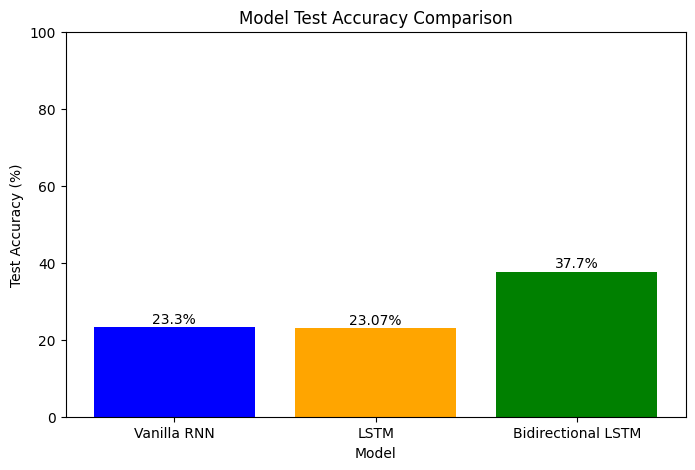

In [17]:
import matplotlib.pyplot as plt

# Model names and their test accuracies
models = ['Vanilla RNN', 'LSTM', 'Bidirectional LSTM']
accuracies = [23.3, 23.07, 37.7]

plt.figure(figsize=(8, 5))
plt.bar(models, accuracies, color=['blue', 'orange', 'green'])
plt.title('Model Test Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100)

# Add value labels on top of each bar
for i, v in enumerate(accuracies):
    plt.text(i, v + 1, f'{v}%', ha='center')

plt.show()

**Comment on the perfomance of all the models**

RNN accuracy reached 23.3% and LSTM molde performed slightly better with 23.07%. The biderectional LSTM is the best overall achiving 37.7%.